# Dữ liệu Diabetes Prediction (100.000 mẫu)
**Nguồn trong đề:** Lab 2 — bài tập 2.1.4 (cây quyết định, rừng cây) và 2.2.3 (SVM)

Notebook độc lập cho một tập dữ liệu; code lấy từ các ô tương ứng của notebook Lab2 (giữ nguyên, ô nào chỉnh có ghi `# [Chỉnh]`).

In [1]:
# Thư viện dùng chung (đề import rải rác ở nhiều ô; gom lại để notebook chạy độc lập)
import os
if os.path.basename(os.getcwd()) == 'notebooks':   # chạy notebook từ thư mục notebooks/ thì lùi ra thư mục gốc chứa data/
    os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import matplotlib as mpl
import graphviz
from sklearn import tree, svm
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
diab = pd.read_csv('data/diabetes_prediction_dataset.csv')
print(diab.shape)
print("Giá trị thiếu:", diab.isnull().sum().sum(), "| dòng trùng:", diab.duplicated().sum())
print(diab['diabetes'].value_counts())
# Mã hóa biến phân loại (gender, smoking_history)
diab = pd.get_dummies(diab, columns=['gender','smoking_history'], drop_first=True)
Xd = diab.drop(columns='diabetes'); yd = diab['diabetes']
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=24, stratify=yd)
Xd.head()

(100000, 9)
Giá trị thiếu: 0 | dòng trùng: 3854
diabetes
0    91500
1     8500
Name: count, dtype: int64


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,False,False,False,False,False,True,False
1,54.0,0,0,27.32,6.6,80,False,False,False,False,False,False,False
2,28.0,0,0,27.32,5.7,158,True,False,False,False,False,True,False
3,36.0,0,0,23.45,5.0,155,False,False,True,False,False,False,False
4,76.0,1,1,20.14,4.8,155,True,False,True,False,False,False,False


Cây quyết định - tham số tốt nhất: {'max_depth': 10}  AUC(CV) = 0.9738
Accuracy trên tập test: 0.9721


Random Forest - tham số tốt nhất: {'max_depth': 8, 'n_estimators': 200}  AUC(CV) = 0.9684
Accuracy trên tập test: 0.9726
              precision    recall  f1-score   support

           0       0.97      1.00      0.99     18300
           1       1.00      0.68      0.81      1700

    accuracy                           0.97     20000
   macro avg       0.99      0.84      0.90     20000
weighted avg       0.97      0.97      0.97     20000



<Axes: title={'center': 'Feature importance - Diabetes'}>

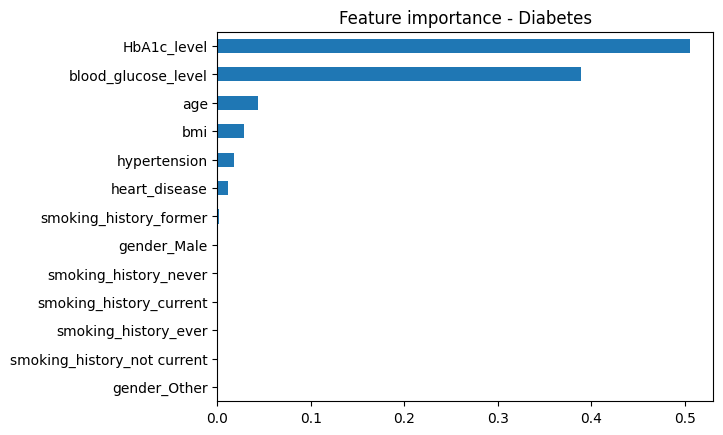

In [3]:
gs_d = GridSearchCV(tree.DecisionTreeClassifier(random_state=24),
                    {'max_depth':[1,2,3,4,5,6,8,10]}, scoring='roc_auc', cv=4, return_train_score=True)
gs_d.fit(Xd_tr, yd_tr)
print("Cây quyết định - tham số tốt nhất:", gs_d.best_params_, " AUC(CV) = %.4f" % gs_d.best_score_)
print("Accuracy trên tập test: %.4f" % accuracy_score(yd_te, gs_d.best_estimator_.predict(Xd_te)))

gs_drf = GridSearchCV(RandomForestClassifier(random_state=4, n_jobs=-1),
                      {'n_estimators':[50,100,200], 'max_depth':[5,8,None]}, scoring='roc_auc', cv=4)
gs_drf.fit(Xd_tr, yd_tr)
print("Random Forest - tham số tốt nhất:", gs_drf.best_params_, " AUC(CV) = %.4f" % gs_drf.best_score_)
pred = gs_drf.best_estimator_.predict(Xd_te)
print("Accuracy trên tập test: %.4f" % accuracy_score(yd_te, pred))
print(classification_report(yd_te, pred))
pd.Series(gs_drf.best_estimator_.feature_importances_, index=Xd.columns).sort_values().plot.barh(title='Feature importance - Diabetes')

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# dùng lại Xd_tr, Xd_te, yd_tr, yd_te (đã xử lý ở bài 2.1.4)
# SVM huấn luyện chậm với 80.000 mẫu nên chỉ lấy ngẫu nhiên 10.000 mẫu của tập train để tìm tham số; đánh giá trên toàn bộ tập test
Xs = Xd_tr.sample(10000, random_state=24); ys = yd_tr.loc[Xs.index]
# SVM nhạy với thang đo nên chuẩn hóa bằng StandardScaler
pipe = make_pipeline(StandardScaler(), svm.SVC())
param = {'svc__kernel':['linear','rbf'], 'svc__C':[0.1,1,10], 'svc__gamma':['scale']}
gs_sd = GridSearchCV(pipe, param, cv=3, scoring='accuracy')
gs_sd.fit(Xs, ys)
print("Tham số tốt nhất:", gs_sd.best_params_)
print("Accuracy CV: %.4f" % gs_sd.best_score_)
pred = gs_sd.predict(Xd_te)
print("Accuracy test: %.4f" % accuracy_score(yd_te, pred))
print(confusion_matrix(yd_te, pred))
print(classification_report(yd_te, pred))

Tham số tốt nhất: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Accuracy CV: 0.9596


Accuracy test: 0.9608
[[18221    79]
 [  705   995]]
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     18300
           1       0.93      0.59      0.72      1700

    accuracy                           0.96     20000
   macro avg       0.94      0.79      0.85     20000
weighted avg       0.96      0.96      0.96     20000

